In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

## STEP - 1 LOAD THE DATA 

In [2]:
df = pd.read_csv("student-mat.csv", sep=";")
print(df.shape)
df.head()

(395, 33)


,school,sex,age,address,famsize,Pstatus,Medu,Fedu,Mjob,Fjob,...,famrel,freetime,goout,Dalc,Walc,health,absences,G1,G2,G3
0,GP,F,18,U,GT3,A,4,4,at_home,teacher,...,4,3,4,1,1,3,6,5,6,6
1,GP,F,17,U,GT3,T,1,1,at_home,other,...,5,3,3,1,1,3,4,5,5,6
2,GP,F,15,U,LE3,T,1,1,at_home,other,...,4,3,2,2,3,3,10,7,8,10
3,GP,F,15,U,GT3,T,4,2,health,services,...,3,2,2,1,1,5,2,15,14,15
4,GP,F,16,U,GT3,T,3,3,other,other,...,4,3,2,1,2,5,4,6,10,10


**OBSERVATION - HERE, the file has rows - 395 , and column - 33 , and values are sperated by (;)**

## STEP - 2 DATA QUALITY CHECKS 

In [3]:
print("Missing values:", df.isnull().sum().sum())
print("Duplicate rows:", df.duplicated().sum())
print("Students with final grade 0:", (df["G3"] == 0).sum())
df["G3"].describe()

Missing values: 0
Duplicate rows: 0
Students with final grade 0: 38


count    395.000000
mean      10.415190
std        4.581443
min        0.000000
25%        8.000000
50%       11.000000
75%       14.000000
max       20.000000
Name: G3, dtype: float64

**checking data quality we have 0 missing values , 0 duplicates , but 38 students have g3 = 0
these are propably the student who dropped out or did not attempt the exam**

## STEP - 3 EXPLROING THE  TARGET AND CORRELATIONS 

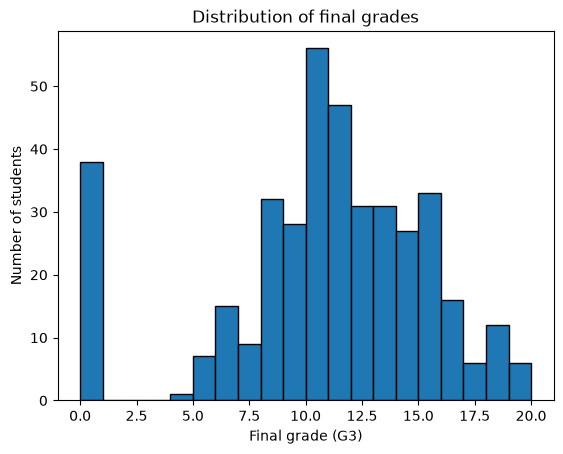

failures     -0.36
age          -0.16
goout        -0.13
traveltime   -0.12
health       -0.06
Dalc         -0.05
Walc         -0.05
freetime      0.01
absences      0.03
famrel        0.05
studytime     0.10
Fedu          0.15
Medu          0.22
G1            0.80
G2            0.90
Name: G3, dtype: float64


In [4]:
plt.hist(df["G3"], bins=20, edgecolor="black")
plt.xlabel("Final grade (G3)")
plt.ylabel("Number of students")
plt.title("Distribution of final grades")
plt.show()

correlations = df.select_dtypes(include="number").corr()["G3"].drop("G3").sort_values()
print(correlations.round(2))

**Observation (histogram): Most grades fall between 5 and 20, with the highest bar at about 10-11 (roughly 56 students).
There is a separate spike of 38 students at 0, and almost nobody scored between 1 and 4, so the zeros look like a different group (likely dropouts or absent students) and not very low scorers.**

**Observation (correlations with G3):**
**- G2 (0.90) and G1 (0.80) are very strongly linked to G3, because they are earlier grades from the same course.**
**- failures has the strongest link among the other features (-0.36): more past failures go with lower grades.**
- **Other weak links: Medu 0.22, Fedu 0.15, studytime 0.10 (positive); age -0.16, goout -0.13, traveltime -0.12 (negative).**
- **absences has almost no straight-line link (0.03).**

Correlation only measures straight-line relationships and does not prove cause.

## STEP - 4 PREPOCESSING TWO CASES 

In [5]:
# text columns become 0/1 columns because models only understand numbers
df_encoded = pd.get_dummies(df, drop_first=True)

y = df_encoded["G3"]
X_all = df_encoded.drop("G3", axis=1)                    
X_early = df_encoded.drop(["G3", "G1", "G2"], axis=1)    
cases = {"with G1, G2": X_all, "without G1, G2": X_early}

**Two cases -- models only understand numbers , so i used 'pd.get_dummies'  to turn text columns 
for ex - school, student, sex , Mjob into 0/1 columns.** 

*G1 and G2 are only known after the term has started. because the goal is to predict performance early , so i made
two versions of the inputs -*

**with G1, G2 - more accurate but available later 
without G1 , G2 - uses only background and habits , so it could be used early**



                                                                                                 
                                                                                                 

## STEP - 5 MODEL AND VALIDATION SETUP

In [6]:
from sklearn.model_selection import train_test_split, cross_val_score, KFold, GridSearchCV
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LinearRegression, Ridge
from sklearn.tree import DecisionTreeRegressor
from sklearn.ensemble import RandomForestRegressor, GradientBoostingRegressor
from sklearn.metrics import mean_squared_error, r2_score
from sklearn.inspection import permutation_importance

In [7]:
models = {
    "Linear Regression": make_pipeline(StandardScaler(), LinearRegression()),
    "Ridge": make_pipeline(StandardScaler(), Ridge(alpha=10)),
    "Decision Tree": DecisionTreeRegressor(max_depth=4, random_state=42),
    "Random Forest": RandomForestRegressor(random_state=42),
    "Gradient Boosting": GradientBoostingRegressor(random_state=42),
}
folds = KFold(n_splits=5, shuffle=True, random_state=42)

**Choosing the models so , i have used 5 models : linear regression , ridge, decision tree, random forest and gradient boosting.**

**both linear models use a srandardscaler beacause they are sensitive to the size of the number for example - absence go
up to 93 but family relationship only to 5 . tree-based models do not need scaling
also used 5 fold cross validation on the training data to get a steadier score than single small test set.**

## STEP - 6 TRAIN AND EVALUATE DATA 

In [8]:
rows = []
split_data = {}     

for case_name, X in cases.items():
    X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)
    split_data[case_name] = (X_train, X_test, y_train, y_test)

    
    average_guess = np.full(len(y_test), y_train.mean())
    rows.append([case_name, "Baseline (average)", None,
                 np.sqrt(mean_squared_error(y_test, average_guess)),
                 r2_score(y_test, average_guess)])

    for model_name, model in models.items():
        cv_scores = cross_val_score(model, X_train, y_train, cv=folds,
                                    scoring="neg_root_mean_squared_error")
        cv_rmse = -cv_scores.mean()      

        model.fit(X_train, y_train)
        predictions = model.predict(X_test)
        test_rmse = np.sqrt(mean_squared_error(y_test, predictions))
        test_r2 = r2_score(y_test, predictions)

        rows.append([case_name, model_name, cv_rmse, test_rmse, test_r2])

results = pd.DataFrame(rows, columns=["case", "model", "cv_rmse", "test_rmse", "test_r2"]).round(3)
results.to_csv("results.csv", index=False)
results

,case,model,cv_rmse,test_rmse,test_r2
0,"with G1, G2",Baseline (average),NaN,4.550,-0.010
1,"with G1, G2",Linear Regression,1.987,2.378,0.724
2,"with G1, G2",Ridge,1.974,2.357,0.729
3,"with G1, G2",Decision Tree,1.823,2.490,0.698
4,"with G1, G2",Random Forest,1.503,1.949,0.815
5,"with G1, G2",Gradient Boosting,1.575,2.003,0.804
6,"without G1, G2",Baseline (average),NaN,4.550,-0.010
7,"without G1, G2",Linear Regression,4.607,4.196,0.141
8,"without G1, G2",Ridge,4.537,4.179,0.148
9,"without G1, G2",Decision Tree,4.510,4.557,-0.013


**baseline -- Model always guesses the average grade has an Rmse of 4.550 andan R2 of about -0.010 so any usefull model must beat that.**

With G1 and G2 (test RMSE / test R² / cross-validation RMSE):
- Random Forest: 1.949 / 0.815 / 1.503 (best)
- Gradient Boosting: 2.003 / 0.804 / 1.575
- Ridge: 2.357 / 0.729 / 1.974
- Linear Regression: 2.378 / 0.724 / 1.987
- Decision Tree: 2.490 / 0.698 / 1.823


Random Forest's error is about 57% lower than the baseline. It is also best on cross-validation, so the ranking is consistent.

Without G1 and G2:
- Random Forest: 3.935 / 0.245 / 3.967 (best)
- Gradient Boosting: 4.027 / 0.209 / 4.029
- Ridge: 4.179 / 0.148 / 4.537
- Linear Regression: 4.196 / 0.141 / 4.607
- Decision Tree: 4.557 / -0.013 / 4.510

Even the best model lowers the error by only about 13.5% compared with the baseline (3.935 vs 4.550). The Decision Tree is no better than guessing.


**without earlier grades, background information alone explains only a small part of the differences between students.
Because the test set has only 79 students, small differences between models should not be over-trusted**



## STEP - 7 COMPARE MODELS IN PLOT

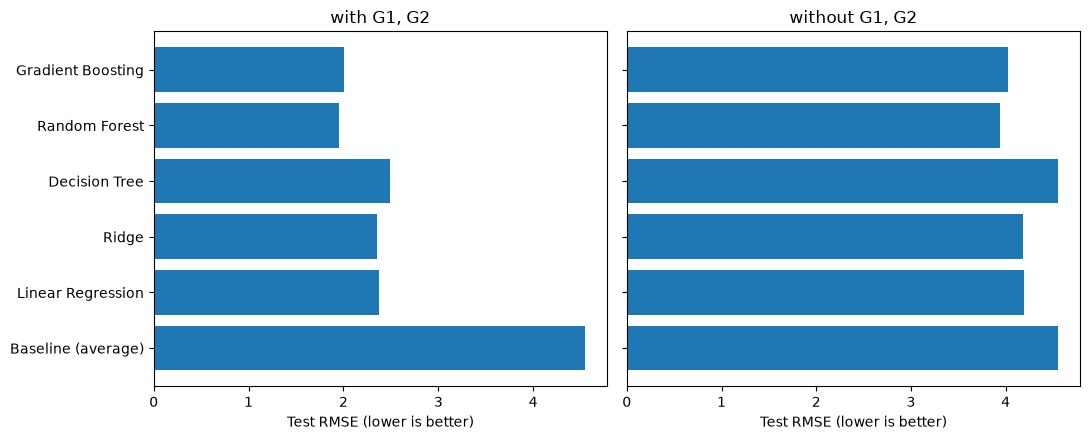

In [9]:
fig, axes = plt.subplots(1, 2, figsize=(11, 4.5), sharey=True)
for axis, case_name in zip(axes, cases):
    part = results[results["case"] == case_name]
    axis.barh(part["model"], part["test_rmse"])
    axis.set_title(case_name)
    axis.set_xlabel("Test RMSE (lower is better)")
plt.tight_layout()
plt.show()

**OBSERVATION - THE CHARTS CONFIRM THE TABLE. ERROR ARE MUCH LOWER WITH G1 AND G2 THAN WITHOUT THEM, AND RANDOM FOREST HAS THE LOWEST TEST ERROR IN BOTH CASES.**

**Without G1 and G2, the bars are close to the baseline bar of 4.55  Random Forest is the lowest at 3.935 (about 13.5% below the baseline), and the Decision Tree (4.557) is no better than the baseline.**

## STEP - 8 PREDICTED AND ACTUAL

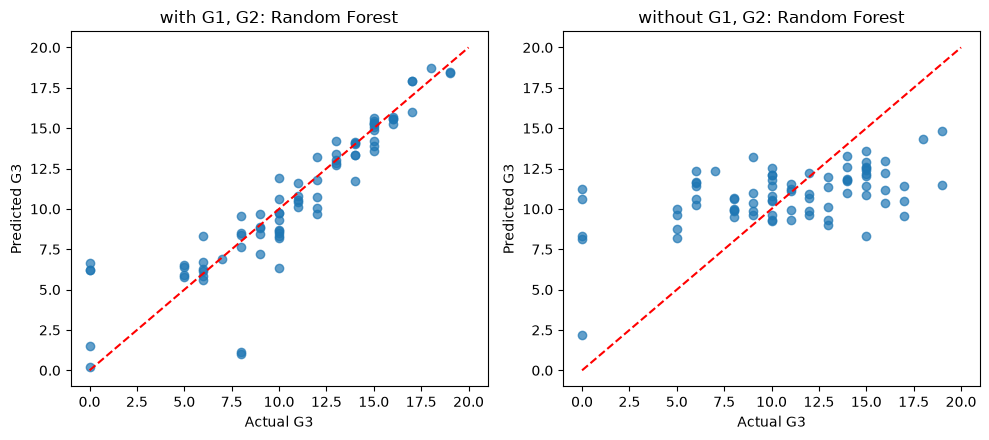

In [10]:
fig, axes = plt.subplots(1, 2, figsize=(10, 4.5))
for axis, case_name in zip(axes, cases):
    X_train, X_test, y_train, y_test = split_data[case_name]
    predictions = models["Random Forest"].fit(X_train, y_train).predict(X_test)

    axis.scatter(y_test, predictions, alpha=0.7)
    axis.plot([0, 20], [0, 20], "r--")        # perfect predictions would sit on this line
    axis.set_title(case_name + ": Random Forest")
    axis.set_xlabel("Actual G3")
    axis.set_ylabel("Predicted G3")
plt.tight_layout()
plt.show()

**PREDICTED AND ACTUAL GRADES**

**With G1 and G2:** the points follow the red line closely, so predictions are close to the real grades.
Exceptions: two students with an actual grade of 8 were predicted at about 1 and the zero-grade students are mostly missed (three were predicted around 6.2-6.6 one about 1.5, and only one close to 0).

**Without G1 and G2:** the points are spread widely around the line. Predictions are squeezed into a narrow band of roughly 8 to 15 whatever the real grade is.

- Students who really scored high (15-19) are under-predicted
- The 5 zero-grade students were predicted between about 2.2 and 11.2, so the model does not recognise them.



## STEP - 9 FEATURE IMPORTANCE

with G1, G2 - top 8:
G2                4.129
absences          0.565
studytime         0.087
age               0.060
famrel            0.043
health            0.015
activities_yes    0.013
Walc              0.007
dtype: float64

without G1, G2 - top 8:
failures           0.587
absences           0.384
goout              0.189
schoolsup_yes      0.100
sex_M              0.098
Medu               0.072
Fjob_teacher       0.041
guardian_mother    0.039
dtype: float64



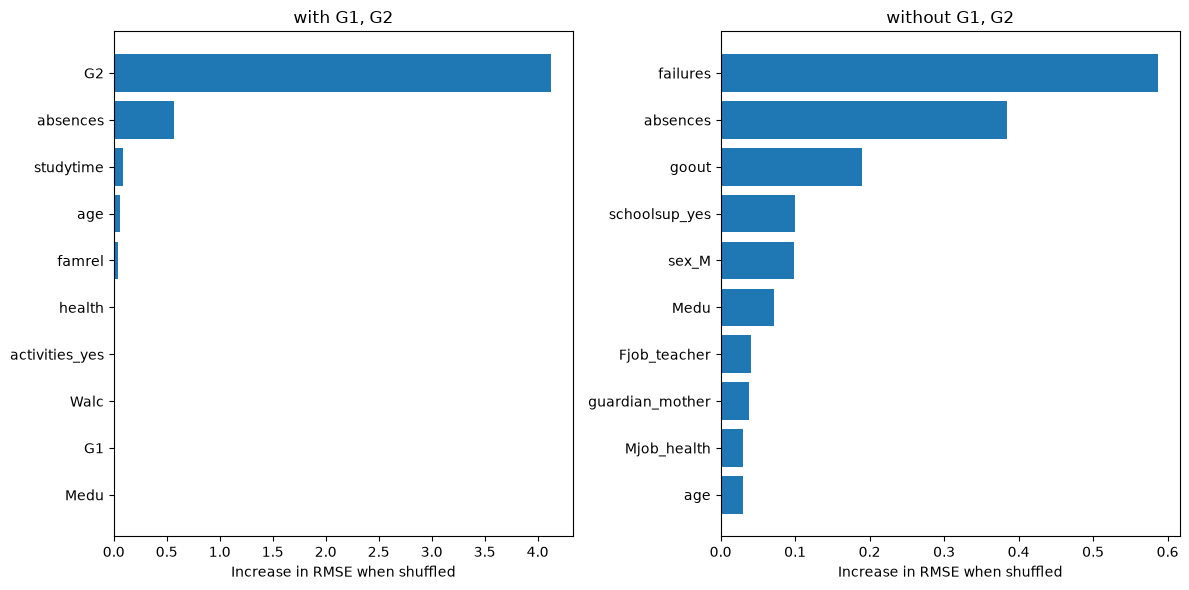

In [11]:
fig, axes = plt.subplots(1, 2, figsize=(12, 6))
for axis, case_name in zip(axes, cases):
    X_train, X_test, y_train, y_test = split_data[case_name]
    forest = models["Random Forest"].fit(X_train, y_train)


    result = permutation_importance(forest, X_test, y_test, n_repeats=30, random_state=42,
                                    scoring="neg_root_mean_squared_error")
    importance = pd.Series(result.importances_mean, index=X_test.columns)
    importance = importance.sort_values(ascending=False)

    print(case_name, "- top 8:")
    print(importance.head(8).round(3))
    print()

    top10 = importance.head(10)
    axis.barh(top10.index[::-1], top10.values[::-1])
    axis.set_title(case_name)
    axis.set_xlabel("Increase in RMSE when shuffled")
plt.tight_layout()
plt.show()

I used permutation importance on the test set : one column is shuffled at a time , and a large rise in error means the model relied on that column more.

**with G1 and G2-- g2 is far ahead of everything else (4.129). 'absence' is second (0.565) the rest are small and close to noise.**

**without G1 and G2 -- failure - (0.587) and absences (0.384), lead, followed by goout (0.189) , schoolsup_yes (0.100) , sex_M - 0.098 and Medu - 0.072**

_ **absence has almost no strainght-line correlation with G3 (0.03) but is important to the model so the model uses a pattern that simple correlation misses.** 

- **importance shows what model uses, not what causes grades to change.
for example - schoolsup_yes likely ranks high because extra support goes to student who are already strggling.**

- **Names like sex_M appear because get_dummies splits categories into separate columns.**


## STEP - 10 ZERO GRADE STUDENT 

In [12]:
X_train, X_test, y_train, y_test = split_data["without G1, G2"]
predictions = models["Random Forest"].fit(X_train, y_train).predict(X_test)
not_zero = y_test > 0

print("Zero-grade students in test set:", (~not_zero).sum())
print("All students    RMSE:", round(np.sqrt(mean_squared_error(y_test, predictions)), 2))
print("Excluding zeros RMSE:", round(np.sqrt(mean_squared_error(y_test[not_zero], predictions[not_zero])), 2),
      " R2:", round(r2_score(y_test[not_zero], predictions[not_zero]), 2))

Zero-grade students in test set: 5
All students    RMSE: 3.94
Excluding zeros RMSE: 3.37  R2: 0.16


**Observation - the test set contain 5 students with a grade of 0 . removing them lower the Rmse from
3.94 to 3.37 , but R2 falls from 0.25 to 0.16 so the zero-grade students make the error larger
but they are not the main early prediction is weak . the model is also weak for the other
students**




## STEP - 11 TUNING THE RANDOM FOREST

In [13]:
search = GridSearchCV(RandomForestRegressor(random_state=42),
                      {"min_samples_leaf": [1, 3, 5, 10], "max_depth": [None, 5, 10]},
                      cv=folds, scoring="neg_root_mean_squared_error")
search.fit(X_train, y_train)          # uses only the training data

tuned_predictions = search.predict(X_test)
print("Best settings:", search.best_params_)
print("Tuned test RMSE:", round(np.sqrt(mean_squared_error(y_test, tuned_predictions)), 2),
      " R2:", round(r2_score(y_test, tuned_predictions), 2))

Best settings: {'max_depth': 5, 'min_samples_leaf': 1}
Tuned test RMSE: 3.98  R2: 0.23


**trying to imporve the random forest , i used GridSearch on the training data to test different settings 
min_sample_leaf and max_depth**

**observation - The best settings gavea test Rmse of 3.98 and R2 of 0.23 , slightly wore than
the default forest (3.94 and 0.25) 
tuning did not help , which suggests the limit comes from the data few students and background
feature , not from the model settings**



    

## Conclusions
1. Earlier grades, especially G2, predict the final grade well (best R2 about 0.82).
2. Without earlier grades, prediction is weak (best R2 about 0.25) but still better than guessing the average.
3. Past failures and absences are the most useful early signals.
4. Tuning and removing zero-grade students did not change this picture.

## Limitations
- Only 395 students and a test set of 79, so model rankings can change with a different split.
- 38 students with a grade of 0 are hard to predict.
- Feature importance does not show cause and effect.
- sex is used as a feature, so the model should not be used to treat students differently on that basis.
- The data comes from two schools in Portugal and may not apply elsewhere.